# 04 Era removal

Phase 3's encoder recognises players well, but its embedding gives away the decade: a linear probe reads the era at 0.323 against a chance level of 0.20, while B2's raw z-scores read 0.190. Phase 4 tries to remove that era signal so comps can cross eras, without losing the Phase 3 retrieval. Two methods are compared. The **adversary** retrains the encoder with an extra "era head" behind a gradient reversal layer, so the encoder is pushed to make the decade unpredictable. **Season centring** retrains nothing: it subtracts a fraction alpha of each season's average embedding (computed over training players) and renormalises.

The adversary was expected to struggle (plan section 2): single-seed trial runs before the search showed that the encoder beats the head it trains against, while a fresh probe still finds the decade. It stays in the search with its default head so the roadmap's method is measured properly over 3 seeds.

This notebook **only reads**. It trains nothing and writes nothing under `reports/` or `models/`: it loads `reports/phase4_search.csv` and the saved weights. Numbers are on the **validation** split, which also chose the method and strength, so they are optimistic. The test split and the five hold-outs are never touched.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from baselines import B2Cosine
from evaluate import SANITY, comp_players, era_and_position
from evaluate_era import (RETRIEVAL_TOLERANCE, SEARCH_CSV, SEEDS, choose, decades_of, era_probe_val,
                          load_adv, load_candidate, splits)

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 140)
df, train, val, trval, pool = splits()
search = pd.read_csv(SEARCH_CSV)
report_text = (ROOT / "reports" / "phase4_era.md").read_text()

agg = (search.groupby(["method", "param"])
       .agg(nonadj=("nonadj_hit10", "mean"), era=("era", "mean"), era_val=("era_val", "mean")).reset_index())
method, param, why = choose(agg)
print(f"{len(search)} search rows. Chosen: {method} {param} ({why})")

24 search rows. Chosen: centring 0.5 (met the era target with the best retrieval)


## 1. Adversary training

One adversary run (lambda 1.0, seed 2026), from its checkpoint's saved history. Lambda ramps up from 0, so the encoder learns players first. The era head's accuracy is measured on training pairs. The decades are not equal in size, so 0.20 is only approximate chance for the head.

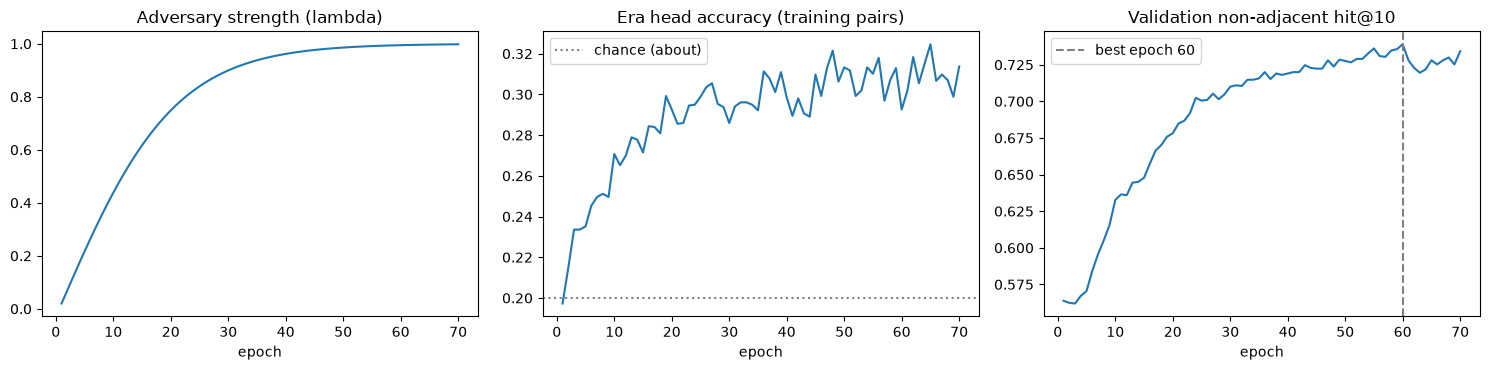

Ran 70 epochs; era head accuracy at the best epoch 0.293


In [2]:
adv = load_adv(1.0, 2026)
h = pd.DataFrame(adv.history["contrastive"])
best_epoch = int(h.loc[h["val_nonadj_hit10"].idxmax(), "epoch"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(h["epoch"], h["lambda"]); axes[0].set(title="Adversary strength (lambda)", xlabel="epoch")
axes[1].plot(h["epoch"], h["era_head_acc"]); axes[1].axhline(0.20, c="grey", ls=":", label="chance (about)")
axes[1].set(title="Era head accuracy (training pairs)", xlabel="epoch"); axes[1].legend()
axes[2].plot(h["epoch"], h["val_nonadj_hit10"]); axes[2].axvline(best_epoch, c="grey", ls="--", label=f"best epoch {best_epoch}")
axes[2].set(title="Validation non-adjacent hit@10", xlabel="epoch"); axes[2].legend()
plt.tight_layout(); plt.show()
print(f"Ran {len(h)} epochs; era head accuracy at the best epoch {h.loc[h['epoch'] == best_epoch, 'era_head_acc'].iloc[0]:.3f}")

## 2. The trade-off

Every candidate, averaged over its 3 seeds: mean era probe (left is better) against mean non-adjacent hit@10 (up is better). The target is an era probe at or below 0.25 with retrieval no more than 0.012 below the control. The winner is the candidate in the green region with the best retrieval.

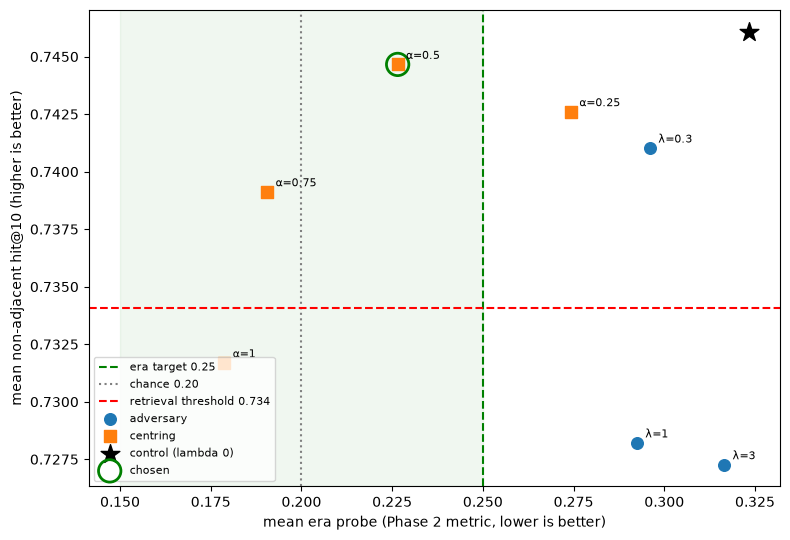

,method,param,nonadj,era,era_val
0,adversary,0.00,0.746,0.323,0.281
1,adversary,0.30,0.741,0.296,0.256
2,adversary,1.00,0.728,0.292,0.250
3,adversary,3.00,0.727,0.317,0.275
4,centring,0.25,0.743,0.274,0.248
5,centring,0.50,0.745,0.227,0.231
6,centring,0.75,0.739,0.191,0.217
7,centring,1.00,0.732,0.179,0.228


In [3]:
control = agg[(agg["method"] == "adversary") & (agg["param"] == 0)].iloc[0]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.axvspan(0.15, 0.25, ymin=0, ymax=1, color="green", alpha=0.06)
ax.axvline(0.25, c="green", ls="--", label="era target 0.25")
ax.axvline(0.20, c="grey", ls=":", label="chance 0.20")
ax.axhline(control["nonadj"] - RETRIEVAL_TOLERANCE, c="red", ls="--", label=f"retrieval threshold {control['nonadj'] - RETRIEVAL_TOLERANCE:.3f}")
for m, marker, colour in [("adversary", "o", "tab:blue"), ("centring", "s", "tab:orange")]:
    sub = agg[(agg["method"] == m) & ~((agg["method"] == "adversary") & (agg["param"] == 0))]
    ax.scatter(sub["era"], sub["nonadj"], marker=marker, s=70, c=colour, label=m)
    for _, r in sub.iterrows():
        ax.annotate(f"{'λ' if m == 'adversary' else 'α'}={r['param']:g}", (r["era"], r["nonadj"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.scatter([control["era"]], [control["nonadj"]], marker="*", s=200, c="black", label="control (lambda 0)")
ch = agg[(agg["method"] == method) & (agg["param"] == param)].iloc[0]
ax.scatter([ch["era"]], [ch["nonadj"]], s=260, facecolors="none", edgecolors="green", linewidths=2, label="chosen")
ax.set(xlabel="mean era probe (Phase 2 metric, lower is better)", ylabel="mean non-adjacent hit@10 (higher is better)")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()
display(agg.round(3))

## 3. Probes side by side

Chosen candidate vs control vs B2, scored on the three seed models (B2 has no seeds). The linear era probe is the Phase 2 metric. The validation-only versions are fitted and scored on validation players, who the encoder never trained on. The nonlinear probe uses gradient-boosted trees, which can find curved boundaries a linear probe misses. The last line checks the chosen and control numbers against `reports/phase4_era.md`.

,chosen,control,B2 cosine
"era (train+val, linear)",0.227,0.323,0.190
"era (val only, linear)",0.231,0.281,0.176
"era (val only, nonlinear)",0.319,0.324,0.430
position,0.657,0.656,0.661


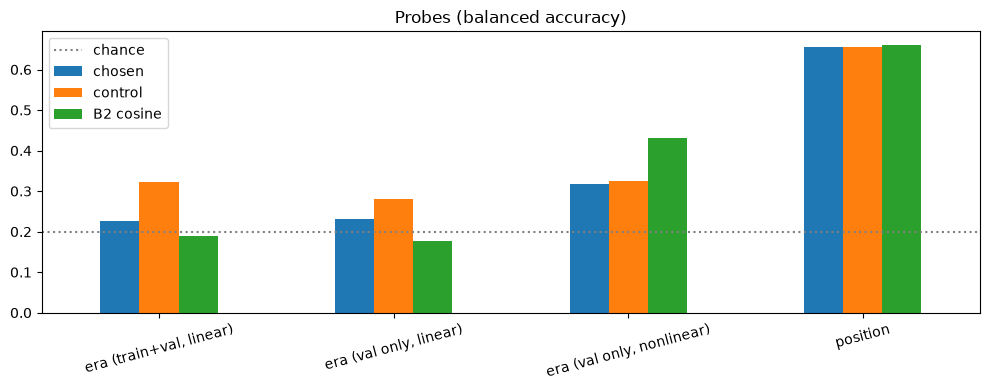

Matches reports/phase4_era.md


In [4]:
chosen = [load_candidate(method, param, s, train) for s in SEEDS]
ctl = [load_adv(0.0, s) for s in SEEDS]
b2 = B2Cosine().fit(train)

def probes(m):
    p = era_and_position(m, trval)
    return {"era (train+val, linear)": p["era"], "era (val only, linear)": era_probe_val(m, val),
            "era (val only, nonlinear)": era_probe_val(m, val, nonlinear=True), "position": p["position"]}

pc = pd.DataFrame([probes(m) for m in chosen]).mean()
p0 = pd.DataFrame([probes(m) for m in ctl]).mean()
pb = pd.Series(probes(b2))
tab = pd.DataFrame({"chosen": pc, "control": p0, "B2 cosine": pb})
display(tab.round(3))

ax = tab.plot.bar(figsize=(10, 4), rot=15, title="Probes (balanced accuracy)")
ax.axhline(0.2, c="grey", ls=":", label="chance"); ax.legend(); plt.tight_layout(); plt.show()

for label, col in [("Era probe, train + val, linear (Phase 2 metric; chance 0.20)", "era (train+val, linear)"),
                   ("Era probe, validation only, linear", "era (val only, linear)"),
                   ("Era probe, validation only, nonlinear (boosted trees)", "era (val only, nonlinear)"),
                   ("Position probe (chance 0.20)", "position")]:
    for cell in (f"{tab.loc[col, 'chosen']:.3f} ±", f"{tab.loc[col, 'control']:.3f} ±"):
        assert f"| {label} |" in report_text and cell in report_text, f"notebook and report disagree on {label}: {cell}"
print("Matches reports/phase4_era.md")

## 4. What centring does

The seed 2026 embedding of every validation season, projected to 2 dimensions with PCA (fitted separately for each model), coloured by decade. A 2D picture throws most of the embedding away, so it is for intuition only (feature note, check 6).

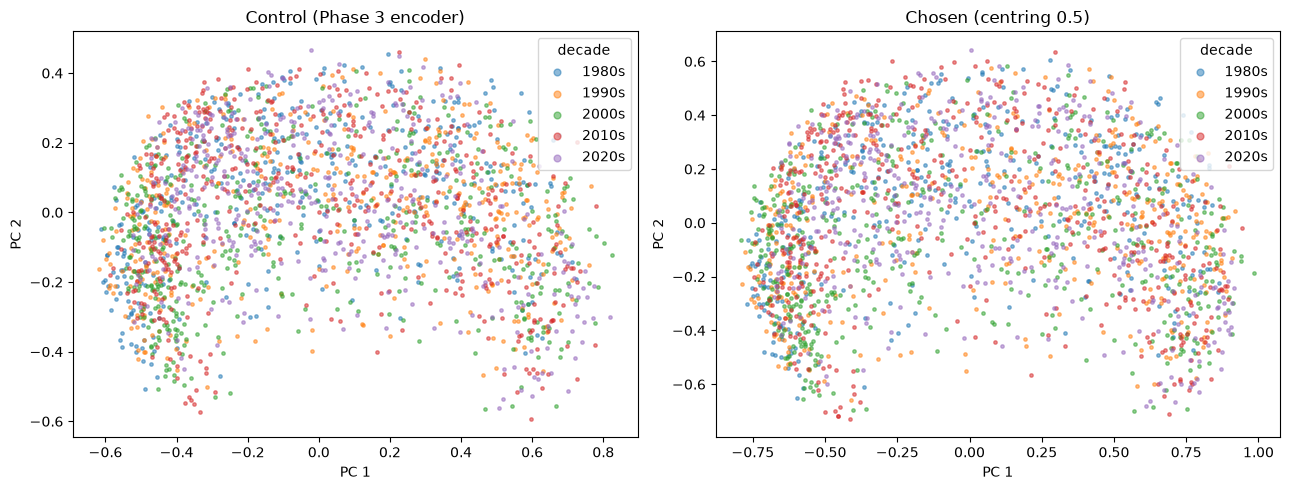

In [5]:
dec = decades_of(val)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, model) in zip(axes, [("Control (Phase 3 encoder)", ctl[0]), (f"Chosen ({method} {param})", chosen[0])]):
    xy = PCA(n_components=2, random_state=0).fit_transform(model.embed(val))
    for d in sorted(set(dec)):
        k = dec == d
        ax.scatter(xy[k, 0], xy[k, 1], s=6, alpha=0.5, label=f"{d}s")
    ax.set(title=title, xlabel="PC 1", ylabel="PC 2"); ax.legend(markerscale=2, title="decade")
plt.tight_layout(); plt.show()

## 5. Comps across eras

Top 10 comp players (each counted once, best-matching season; hold-outs excluded from the pool) for Curry, Magic and Bird, under the control and the chosen candidate (seed 2026), with how many comps come from each decade.

In [6]:
by_name = {v: k for k, v in SANITY.items()}
for name in ["Stephen Curry", "Magic Johnson", "Larry Bird"]:
    q = df[df["player_id"] == by_name[name]]
    rows = []
    for label, model in [("Control", ctl[0]), ("Chosen", chosen[0])]:
        c = comp_players(model, q, pool, n=10)
        counts = Counter(f"{d}s" for d in np.minimum((c["season"] // 10) * 10, 2020))
        rows.append({"model": label, "top 10": ", ".join(f"{p} {s}" for p, s in zip(c["player"], c["season"])),
                     "decades": f"{len(counts)}: " + ", ".join(f"{d} x{n}" for d, n in sorted(counts.items()))})
    print(name)
    display(pd.DataFrame(rows).set_index("model"))

Stephen Curry


,top 10,decades
model,,
Control,"Mo Williams 2010, Ray Allen 2004, Mike James 2006, Jordan Farmar 2012, Jeff Hornacek 1993, Larry Bird 1987, Damian Lillard 2015, Jameer ...","4: 1980s x1, 1990s x2, 2000s x3, 2010s x4"
Chosen,"Mo Williams 2010, Ray Allen 2004, Mike James 2006, Jordan Farmar 2012, Jeff Hornacek 1993, Jameer Nelson 2009, Manu Ginóbili 2008, Damia...","3: 1990s x2, 2000s x4, 2010s x4"


Magic Johnson


,top 10,decades
model,,
Control,"Kevin Johnson 1992, Andre Miller 2002, Deron Williams 2009, Reggie Theus 1986, John Stockton 1999, Tyrese Haliburton 2023, Rod Stricklan...","5: 1980s x1, 1990s x3, 2000s x2, 2010s x2, 2020s x2"
Chosen,"Kevin Johnson 1992, Andre Miller 2001, Deron Williams 2009, Tyrese Haliburton 2023, Reggie Theus 1986, John Stockton 1999, Rod Stricklan...","5: 1980s x1, 1990s x4, 2000s x2, 2010s x2, 2020s x1"


Larry Bird


,top 10,decades
model,,
Control,"Stephen Curry 2023, Ray Allen 2001, Tyler Herro 2023, Clyde Drexler 1995, Antoine Walker 2001, Jamal Mashburn 2003, Paul George 2013, Ni...","4: 1990s x2, 2000s x3, 2010s x1, 2020s x4"
Chosen,"Stephen Curry 2023, Ray Allen 2001, Tyler Herro 2023, Clyde Drexler 1995, Antoine Walker 2001, Jamal Mashburn 2003, Chris Mullin 1990, J...","3: 1990s x4, 2000s x3, 2020s x3"


## 6. Findings

- **Chosen: season centring at alpha 0.5.** No adversary setting reached the 0.25 target, so the choice came from the centring candidates; alpha 0.5 is the one with the best retrieval among those at or below 0.25.
- **The adversary barely moves the era probe.** Its best mean is 0.292 (lambda 1.0), against 0.323 for the control, and it costs retrieval (0.728 against 0.746). Lambda 3.0 reads 0.317, higher than lambda 1.0 (section 2). The era head's training accuracy at the best epoch of the lambda 1.0, seed 2026 run is 0.293 (section 1), and a fresh linear probe on the lambda 1.0 models still reads 0.292 on average (section 2).
- **Centring removes the linear era signal and keeps retrieval.** The era probe falls from 0.323 to 0.227 (B2 reads 0.190) while non-adjacent hit@10 stays at 0.745 against the control's 0.746. Higher alpha lowers the era probe further (0.179 at alpha 1.0) at a growing retrieval cost (0.732).
- **The nonlinear probe still finds the era.** Validation-only boosted trees read 0.319 for the chosen candidate against 0.324 for the control, and 0.430 for B2's raw z-scores (section 3). Centring removes what a linear probe sees, not the decade information as a whole.
- **Comps cross eras no more than before.** The cross-era share of top-10 comps is 0.723 for the chosen candidate against 0.725 for the control, and the era translation test shows no gain: Curry and Bird draw comps from 3 decades (4 under the control), Magic from 5 in both (section 5).
- **Caveat:** these are validation numbers that also chose the method and strength, so they are optimistic. The new sanity comps are unmarked, so there is no sanity verdict yet.